<a href="https://colab.research.google.com/github/RafaelSeri/TP_LABO_MET/blob/main/notebooks/Tp_labo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Grupal — Laboratorio de Métodos Cuantitativos
### FCE UBA · 2do Cuatrimestre 2026

**Integrantes:** Catalina Fiorini · Rafael Seri · Federico Mingorance · Micaela Berzoni · Genaro D'Angelo

**Repositorio:** [github.com/RafaelSeri/TP_LABO_MET](https://github.com/RafaelSeri/TP_LABO_MET)

---

## ¿Por qué la demanda eléctrica?

Cada verano aparecen las mismas noticias: récords de consumo, cortes de luz y redes al límite. Cada invierno, la discusión pasa al gas y a la calefacción. Detrás de esos titulares hay una variable que nadie controla: **la temperatura**.

En este trabajo analizamos la demanda de energía eléctrica en Argentina entre 2005 y 2025 para entender cuánto depende del clima y en qué momentos del año el sistema está más exigido. Esta pregunta no es solo curiosidad: planificar la generación, anticipar picos de consumo y diseñar tarifas depende de saber cómo responde la demanda cuando hace calor o frío.

## Los datos

La base reúne información de **[CAMMESA — Ministerio de Economía]** con: http://argentina.gob.ar/economia

- **Demanda total** y su desagregación en tres segmentos: residencial, comercio e industria, y grandes usuarios.
- **Temperatura promedio** del período.
- **Potencia máxima** registrada.
- **Demanda por empresa distribuidora** (EDENOR, EDESUR, EPEC, etc.), disponible desde 2014.

Los datos tienen tres frecuencias: anual, trimestral y mensual. Teniendo en cuenta las estaciones del año, la serie mensual es la que más información aporta sobre la relación con la temperatura.

## Pregunta que guía el trabajo

> **¿Cuánto influye la temperatura en la demanda eléctrica en Argentina y en qué épocas del año resulta más crítica?**
## Estructura del notebook

1. Carga y exploración inicial de los datos
2. Definición de la pregunta de investigación
3. Transformaciones y resúmenes estadísticos
4. Análisis gráfico
5. Respuesta a la pregunta y conclusiones

# 1. Carga y exploración inicial de los datos.
### 1.1 Carga de los datos

Los datos provienen del informe de actividad económica que publica el Ministerio de Economía, elaborado con datos de **CAMMESA**. Trabajamos con la hoja `1.28 Electricidad`, que contiene la demanda de electricidad en GWh, la temperatura promedio en °C y la potencia máxima en MW.

La hoja no tiene formato de tabla: incluye títulos, una fila de unidades, filas con códigos internos y filas vacías que separan los bloques anual, trimestral y mensual. Por eso la leemos sin encabezado y la recortamos:

1. Tomamos los nombres de las columnas de las filas de títulos de la hoja.
2. Dejamos afuera las columnas de generación por fuente, que no se relacionan con nuestra pregunta.
3. Conservamos solo las filas que tienen un valor numérico de demanda total, lo que elimina títulos, unidades, códigos y filas vacías.

In [60]:
import pandas as pd
import numpy as np

ruta = 'https://github.com/RafaelSeri/TP_LABO_MET/blob/main/DF/actividad_ied.xlsx?raw=1'
crudo = pd.read_excel(ruta, sheet_name='1.28 Electricidad', header=None)

# Nombres: las variables generales están en la fila 4 y las empresas en la fila 5
nombres = list(crudo.iloc[4, 0:7]) + list(crudo.iloc[5, 8:31])

# Columnas 0 a 6 (demanda, temperatura, potencia) y 8 a 30 (empresas)
df = crudo.iloc[:, list(range(0, 7)) + list(range(8, 31))].copy()
df.columns = [str(n).strip() for n in nombres]

# Nos quedamos solo con las filas que tienen un número en Demanda Total
df = df[pd.to_numeric(df['Demanda Total'], errors='coerce').notna()].reset_index(drop=True)

# Las columnas quedaron como texto: las pasamos a número (todas menos Período)
df[df.columns[1:]] = df[df.columns[1:]].apply(pd.to_numeric)

print(df.shape)
df.head()

(435, 30)


,Período,Demanda Total,Demanda Residencial,Comercio e Industria,Grandes Usuarios,Temperatura Promedio,Potencia Máxima,EDE TUCUMAN,EDELAP SA,EDENOR DISTRIBUIDOR,...,ENERGIA DE CATAMARCA S.A.,ENERGIA DE ENTRE RIOS SA,ENERGIA DE MENDOZA SA,ENERGIA SAN JUAN SA EX-EDESSA,EPEC DISTRIBUIDOR,EPEN DISTRIBUIDOR,EPESF DISTRIBUIDOR,RECURSOS Y ENERGIA FORMOSA SA,SECHEEP,SPSE SANTA CRUZ
0,2001,78101.854,NaN,NaN,NaN,18.485333,14061.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2002,76472.890,NaN,NaN,NaN,18.289667,13481.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2003,82213.370,NaN,NaN,NaN,17.816000,14359.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2004,87172.410,NaN,NaN,NaN,18.442667,15032.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2005,92332.950,30086.495,43102.875,19143.58,18.363667,16143.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


4. Eliminamos los registros de 2001 a 2004. En esos años la fuente no desagrega la demanda por tipo de usuario (residencial, comercio e industria, grandes usuarios), así que trabajamos desde 2005 para que todas las variables cubran el mismo período y podamos llevar adelante el análisis planteado.

In [61]:
# Eliminamos 2001-2004: en esos años no hay datos de demanda por segmento
df = df[df['Demanda Residencial'].notna()].reset_index(drop=True)
df.head(30) #compruebo filtrado

,Período,Demanda Total,Demanda Residencial,Comercio e Industria,Grandes Usuarios,Temperatura Promedio,Potencia Máxima,EDE TUCUMAN,EDELAP SA,EDENOR DISTRIBUIDOR,...,ENERGIA DE CATAMARCA S.A.,ENERGIA DE ENTRE RIOS SA,ENERGIA DE MENDOZA SA,ENERGIA SAN JUAN SA EX-EDESSA,EPEC DISTRIBUIDOR,EPEN DISTRIBUIDOR,EPESF DISTRIBUIDOR,RECURSOS Y ENERGIA FORMOSA SA,SECHEEP,SPSE SANTA CRUZ
0,2005,92332.950000,30086.495000,43102.875000,19143.580000,18.363667,16143.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2006,96812.800000,32608.358000,41291.755000,22912.687000,18.575000,17395.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2007,102950.300000,37111.179000,43484.381000,22354.740000,17.650000,18345.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2008,105958.100000,38610.044000,43060.486000,24287.570000,19.050000,19126.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009,104622.400000,39564.998000,42648.252000,22409.150000,18.583333,19566.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2010,110798.400000,42652.349000,44877.591000,23268.460000,18.066667,20843.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2011,116487.900000,44864.373000,46414.037000,25209.490000,18.316667,21564.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2012,121225.000000,47758.776142,47609.042858,25857.181000,18.691667,21949.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2013,125234.334819,50389.163548,48523.871271,26321.300000,18.508333,23794.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2014,126467.080005,51444.141258,49041.038747,25981.900000,18.625000,24034.000000,2544.537005,2378.511734,20695.281360,...,917.436808,2582.879226,3381.433381,1586.920665,8626.852806,871.880839,9288.999704,1179.717698,2435.771533,509.829498


Guardamos la base recortada como `base_limpia.xlsx`. El análisis de este notebook parte siempre del archivo original; este archivo queda en el repositorio como respaldo, para quien quiera usar los datos limpios directamente.

In [62]:
from google.colab import files

df.to_excel('base_limpia.xlsx', index=False)
# files.download('base_limpia.xlsx') esta linea es para guardar el archivo

En una primera versión del trabajo, este recorte (del punto 4) se hizo directamente en Excel y el notebook partía de esa base ya modificada. Decidimos rehacerlo en el código para que quede registrado y explicado dentro del notebook. Así, cualquiera puede ver qué datos dejamos afuera y por qué, y reproducir el proceso desde el archivo original.

### 1.2 Identificación de la frecuencia de cada fila

La base tiene datos con tres frecuencias distintas apilados en una misma tabla: primero los anuales, después los trimestrales y por último los mensuales. Cada uno tiene su propio formato en la columna `Período`:

- **Anual:** el año como número (`2005`).
- **Trimestral:** en números romanos; solo el primer trimestre indica el año (`I 05`, `II`, `III`, `IV`).
- **Mensual:** una fecha completa (`2005-01-01`).

Creamos la columna `Frecuencia` a partir de ese formato. Es más seguro que separar por número de fila: si la base se modifica, la clasificación sigue funcionando.

In [63]:
def clasificar_frecuencia(p):
    if isinstance(p, str):                  # 'I 05', 'II', 'III', 'IV'
        return 'trimestral'
    if isinstance(p, (int, np.integer)):    # 2005, 2006, ...
        return 'anual'
    return 'mensual'                        # lo que queda son las fechas

df['Frecuencia'] = df['Período'].apply(clasificar_frecuencia)

# Verificación: esperamos 21 anuales, 86 trimestrales y 260 mensuales.
df['Frecuencia'].value_counts()

# Segunda verificacion de la clasificacion por las dudas
# for frecuencia, periodos in df.groupby('Frecuencia')['Período'].unique().items():
# print(f'\n{frecuencia.upper()}:')
#  print(periodos)

,count
Frecuencia,
mensual,260
trimestral,86
anual,21


### 1.3 Separación en dos tablas

Las columnas de la base responden a dos temas distintos, así que las separamos:

- **`df_base`**: demanda total, demanda por segmento (residencial, comercio e industria, grandes usuarios), temperatura promedio y potencia máxima. Es la tabla central para responder nuestra pregunta.
- **`df_empresas`**: demanda de cada empresa distribuidora.

Usamos `.copy()` para que cada tabla sea independiente y las modificaciones posteriores no afecten la base original.

In [64]:
#Transformamos la base limpia en dataframe y creamos dos subdataframes
df_base=df[['Período','Frecuencia','Demanda Total', 'Demanda Residencial',
            'Comercio e Industria','Grandes Usuarios','Temperatura Promedio',
            'Potencia Máxima']].copy()
df_empresas=df[['Período','Frecuencia','EDE TUCUMAN','EDELAP SA', 'EDENOR DISTRIBUIDOR',
'EDESAL DISTRIBUIDOR', 'EDESTESA(EMP.DIST.EL.DEL ESTE)',
'EDESUR DISTRIBUIDOR', 'EMP DE ENERGIA DE RIO NEGRO SA',
'EMP DIST ENERG ATLANTICA', 'EMP. DE ENERGIA DE LA RIOJA SA',
'EMP.DIST.ENERGIA DE SALTA', 'EMP.ELECTRIC.DE MISIONES S.A.',
'EMPRESA DIS. S. ESTERO SA', 'EMPRESA JUJENIA DE ENERGIA SA',
'ENERGIA DE CATAMARCA S.A.', 'ENERGIA DE ENTRE RIOS SA',
'ENERGIA DE MENDOZA SA', 'ENERGIA SAN JUAN SA EX-EDESSA',
'EPEC DISTRIBUIDOR', 'EPEN DISTRIBUIDOR', 'EPESF DISTRIBUIDOR',
'RECURSOS Y ENERGIA FORMOSA SA', 'SECHEEP', 'SPSE SANTA CRUZ']].copy()
df_empresas=df_empresas.dropna() #nos quedamos con las filas con datos no nulos
df_empresas=df_empresas.reset_index(drop=True) #reseteo índices

### 1.4 Separación por frecuencia

Para cada tabla creamos tres subconjuntos según la columna `Frecuencia`: anual, trimestral y mensual. Filtrar por esa columna, en lugar de por número de fila, hace que la separación sea correcta aunque la base cambie o se eliminen filas con nulos.

Para responder nuestra pregunta vamos a trabajar principalmente con los **datos mensuales**: la temperatura promedio anual casi no varía de un año a otro, mientras que la mensual muestra con claridad el paso de las estaciones.

In [65]:
# Para cada df, nos quedamos con los datos del período anual, trimestral y mensual
df_base_anual       = df_base[df_base['Frecuencia'] == 'anual'].copy()
df_base_trimestral  = df_base[df_base['Frecuencia'] == 'trimestral'].copy()
df_base_mensual     = df_base[df_base['Frecuencia'] == 'mensual'].copy()  #Tabla que usamremos para analisis

df_empresas_anual      = df_empresas[df_empresas['Frecuencia'] == 'anual'].copy()
df_empresas_trimestral = df_empresas[df_empresas['Frecuencia'] == 'trimestral'].copy()
df_empresas_mensual    = df_empresas[df_empresas['Frecuencia'] == 'mensual'].copy()


### 1.5 Primeras y últimas filas

Revisamos el principio y el final de cada tabla. En la tabla base se ve la estructura apilada: las primeras filas son totales anuales y las últimas son datos mensuales, con valores de un orden de magnitud menor.

In [66]:
df_base.head()

,Período,Frecuencia,Demanda Total,Demanda Residencial,Comercio e Industria,Grandes Usuarios,Temperatura Promedio,Potencia Máxima
0,2005,anual,92332.95,30086.495,43102.875,19143.580,18.363667,16143.0
1,2006,anual,96812.80,32608.358,41291.755,22912.687,18.575000,17395.0
2,2007,anual,102950.30,37111.179,43484.381,22354.740,17.650000,18345.0
3,2008,anual,105958.10,38610.044,43060.486,24287.570,19.050000,19126.0
4,2009,anual,104622.40,39564.998,42648.252,22409.150,18.583333,19566.0


In [67]:
df_empresas.head()

,Período,Frecuencia,EDE TUCUMAN,EDELAP SA,EDENOR DISTRIBUIDOR,EDESAL DISTRIBUIDOR,EDESTESA(EMP.DIST.EL.DEL ESTE),EDESUR DISTRIBUIDOR,EMP DE ENERGIA DE RIO NEGRO SA,EMP DIST ENERG ATLANTICA,...,ENERGIA DE CATAMARCA S.A.,ENERGIA DE ENTRE RIOS SA,ENERGIA DE MENDOZA SA,ENERGIA SAN JUAN SA EX-EDESSA,EPEC DISTRIBUIDOR,EPEN DISTRIBUIDOR,EPESF DISTRIBUIDOR,RECURSOS Y ENERGIA FORMOSA SA,SECHEEP,SPSE SANTA CRUZ
0,2014,anual,2544.537005,2378.511734,20695.281360,1193.612775,746.308529,17088.832858,1263.940622,2626.465450,...,917.436808,2582.879226,3381.433381,1586.920665,8626.852806,871.880839,9288.999704,1179.717698,2435.771533,509.829498
1,2015,anual,2704.468390,2545.617350,22207.382744,1236.492585,757.037308,18064.754754,1364.005442,2773.577417,...,950.285160,2763.273181,3462.140383,1719.146438,8933.013610,946.857694,9720.505696,1227.170328,2592.745982,561.240525
2,2016,anual,2939.882235,2816.603973,24457.502373,1463.685001,748.361903,19477.180554,1420.263874,2807.465483,...,1054.115441,2925.621791,3403.144289,1942.065602,9298.827150,955.509350,10190.968190,1306.644835,2728.039692,576.744343
3,2017,anual,2857.386146,2599.359071,22013.499165,1309.465478,786.936648,17565.433992,1312.805676,2705.760206,...,1002.080749,2821.614678,3361.309857,1873.970624,9121.949346,916.490891,9775.564765,1302.460587,2786.641335,598.480563
4,2018,anual,2804.714500,2669.383878,22229.026813,1270.556777,766.126704,17641.587070,1338.813501,2725.457446,...,1005.302807,2863.528905,3219.126411,1838.278127,9270.803419,905.697463,9860.999109,1353.646156,3005.021072,634.323649


In [68]:
df_base.tail(10)

,Período,Frecuencia,Demanda Total,Demanda Residencial,Comercio e Industria,Grandes Usuarios,Temperatura Promedio,Potencia Máxima
357,2025-11-01 00:00:00,mensual,10711.334192,4656.511036,4027.227775,2027.595381,20.6,23537.0
358,2025-12-01 00:00:00,mensual,13077.047231,6562.097120,4537.296748,1977.653363,25.9,27891.0
359,2026-01-01 00:00:00,mensual,13145.374526,6497.141379,4635.405535,2012.827612,25.1,26716.0
360,2026-02-01 00:00:00,mensual,11780.616317,5561.497525,4284.903268,1934.215524,25.3,28000.0
361,2026-03-01 00:00:00,mensual,11945.035338,5323.151414,4382.336102,2239.547822,23.3,26480.0
362,2026-04-01 00:00:00,mensual,10579.342832,4463.562615,3969.723032,2146.057185,19.7,23251.0
363,2026-05-01 00:00:00,mensual,12151.531183,5825.605102,4075.780308,2250.145773,13.5,24345.0
364,2026-06-01 00:00:00,mensual,12641.171137,6339.790452,4114.308993,2187.071692,12.0,25785.0
365,2026-07-01 00:00:00,mensual,13063.214629,6643.194389,4211.154804,2208.865436,12.5,27189.0
366,2026-08-01 00:00:00,mensual,12432.027715,6093.065132,4100.504724,2238.457859,12.3,24956.0


In [69]:
df_base.tail()

,Período,Frecuencia,Demanda Total,Demanda Residencial,Comercio e Industria,Grandes Usuarios,Temperatura Promedio,Potencia Máxima
362,2026-04-01 00:00:00,mensual,10579.342832,4463.562615,3969.723032,2146.057185,19.7,23251.0
363,2026-05-01 00:00:00,mensual,12151.531183,5825.605102,4075.780308,2250.145773,13.5,24345.0
364,2026-06-01 00:00:00,mensual,12641.171137,6339.790452,4114.308993,2187.071692,12.0,25785.0
365,2026-07-01 00:00:00,mensual,13063.214629,6643.194389,4211.154804,2208.865436,12.5,27189.0
366,2026-08-01 00:00:00,mensual,12432.027715,6093.065132,4100.504724,2238.457859,12.3,24956.0


### 1.6 Estructura de la base

Revisamos las dimensiones de la base y el tipo de dato de cada columna, para detectar columnas que pandas haya interpretado de forma distinta a la esperada.

In [70]:
print('Filas y columnas de la base completa:', df.shape)
print('Filas y columnas de df_base:', df_base.shape)
print('Filas y columnas de df_empresas:', df_empresas.shape)
print()
df_base.dtypes

Filas y columnas de la base completa: (367, 31)
Filas y columnas de df_base: (367, 8)
Filas y columnas de df_empresas: (208, 25)



,0
Período,object
Frecuencia,object
Demanda Total,float64
Demanda Residencial,float64
Comercio e Industria,float64
Grandes Usuarios,float64
Temperatura Promedio,float64
Potencia Máxima,float64


**Estructura de la base**

- La base completa tiene **367 filas y 31 columnas**. `df_base` conserva las 367 filas con 8 columnas, y `df_empresas` tiene 208 filas, porque solo incluye los períodos con datos por empresa.
- Las variables de demanda, temperatura y potencia son de tipo `float64`, como se esperaba.
- La columna `Período` es de tipo `object` porque mezcla tres tipos de dato distintos: números enteros (años), textos (trimestres) y fechas (meses). Por eso no se puede usar directamente como fecha. Más adelante, en los datos mensuales, la convertimos a tipo fecha.

### 1.7 Control de consistencia entre frecuencias

Verificamos que la suma de los trimestres y la suma de los meses de cada año coincidan con el **dato anual**.


---


Calculamos la diferencia porcentual para cada año completo y mostramos la mayor diferencia encontrada en cada columna de demanda.

In [71]:
anual      = df_base['Frecuencia'] == 'anual'
trimestral = df_base['Frecuencia'] == 'trimestral'
mensual    = df_base['Frecuencia'] == 'mensual'

# Extraer el año de los períodos trimestrales
# Por ejemplo, 'I 05' corresponde al año 2005.
# Si el período no incluye el año, devuelve np.nan para completarlo posteriormente.

def anio_trimestre(p):
    partes = str(p).split()
    if len(partes) == 2:
        return 2000 + int(partes[1])
    return pd.NA

# Crear la columna Año con tipo entero nullable
df_base['Año'] = pd.Series(pd.NA, index=df_base.index, dtype='Int64')

# Asignar el año según la frecuencia
df_base.loc[anual, 'Año'] = pd.to_numeric(df_base.loc[anual, 'Período']).astype('Int64')

df_base.loc[mensual, 'Año'] = pd.to_datetime(df_base.loc[mensual, 'Período']).dt.year.astype('Int64')

df_base.loc[trimestral, 'Año'] = (df_base.loc[trimestral, 'Período'].apply(anio_trimestre).astype('Int64'))

# Completar los años de los trimestres siguientes
df_base.loc[trimestral, 'Año'] = (df_base.loc[trimestral, 'Año'].ffill())

# Verificar registros por año y frecuencia
print(df_base.groupby(['Frecuencia', 'Año']).size().unstack(level=0).head())

# ========================================
# Crear la columna Año en df_empresas
# ========================================

anual_emp      = df_empresas['Frecuencia'] == 'anual'
trimestral_emp = df_empresas['Frecuencia'] == 'trimestral'
mensual_emp    = df_empresas['Frecuencia'] == 'mensual'

# Crear la columna Año
df_empresas['Año'] = pd.Series(
    pd.NA, index=df_empresas.index, dtype='Int64'
)

# Extraer el año de los períodos anuales
df_empresas.loc[anual_emp, 'Año'] = pd.to_numeric(df_empresas.loc[anual_emp, 'Período']).astype('Int64')

# Extraer el año de los períodos mensuales
df_empresas.loc[mensual_emp, 'Año'] = pd.to_datetime(df_empresas.loc[mensual_emp, 'Período']).dt.year.astype('Int64')

# Extraer el año de los períodos trimestrales
df_empresas.loc[trimestral_emp, 'Año'] = (df_empresas.loc[trimestral_emp, 'Período'].apply(anio_trimestre)
    .astype('Int64')
)

# Completar el año en los trimestres siguientes
df_empresas.loc[trimestral_emp, 'Año'] = (df_empresas.loc[trimestral_emp, 'Año'].ffill())

# Verificar cantidad de registros por año y frecuencia
print(df_empresas.groupby(['Frecuencia', 'Año']).size().unstack(level=0).head())

Frecuencia  anual  mensual  trimestral
Año                                   
2005          1.0     12.0         4.0
2006          1.0     12.0         4.0
2007          1.0     12.0         4.0
2008          1.0     12.0         4.0
2009          1.0     12.0         4.0
Frecuencia  anual  mensual  trimestral
Año                                   
2014          1.0     12.0         NaN
2015          1.0     12.0         4.0
2016          1.0     12.0         4.0
2017          1.0     12.0         4.0
2018          1.0     12.0         4.0


**Interpretación del resultado**

La tabla de `df_base` muestra que, entre 2005 y 2009, hay un registro anual, 12 registros mensuales y cuatro registros trimestrales por año. Esto indica que existe consistencia en la cantidad de registros disponibles para cada frecuencia.

Por su parte, en `df_empresas`, entre 2015 y 2018 se observa la misma cantidad de registros por frecuencia. Sin embargo, en 2014 no hay registros trimestrales disponibles, por lo que ese año no cuenta con información completa para realizar el control de consistencia entre las tres frecuencias.


In [72]:
cols_suma = ['Demanda Total', 'Demanda Residencial', 'Comercio e Industria', 'Grandes Usuarios']

dato_anual = df_base[anual].set_index('Año')[cols_suma]

# Sumamos por año y nos quedamos solo con los años completos
suma_trim = df_base[trimestral].groupby('Año')[cols_suma].sum()
filas_trim = df_base[trimestral].groupby('Año').size()
suma_trim = suma_trim[filas_trim == 4]

suma_mens = df_base[mensual].groupby('Año')[cols_suma].sum()
filas_mens = df_base[mensual].groupby('Año').size()
suma_mens = suma_mens[filas_mens == 12]

# Diferencia porcentual respecto del dato anual
dif_trim = ((suma_trim - dato_anual) / dato_anual * 100).dropna()
dif_mens = ((suma_mens - dato_anual) / dato_anual * 100).dropna()

print('Mayor diferencia (%) entre la suma de trimestres y el dato anual:')
print(dif_trim.abs().max().round(3))
print('\nMayor diferencia (%) entre la suma de meses y el dato anual:')
print(dif_mens.abs().max().round(3))

Mayor diferencia (%) entre la suma de trimestres y el dato anual:
Demanda Total           0.001
Demanda Residencial     0.045
Comercio e Industria    0.919
Grandes Usuarios        2.032
dtype: float64

Mayor diferencia (%) entre la suma de meses y el dato anual:
Demanda Total           0.001
Demanda Residencial     0.045
Comercio e Industria    0.919
Grandes Usuarios        2.032
dtype: float64


**Resultado del control de consistencia**

La demanda total presenta una diferencia porcentual máxima de 0,001 % respecto del dato anual, mientras que en la demanda residencial la diferencia alcanza el 0,045 %. Estos resultados indican una elevada consistencia entre las distintas frecuencias para ambas variables.

En cambio, se observan diferencias mayores en los segmentos de Comercio e Industria, con un máximo de 0,919 %, y Grandes Usuarios, con un máximo de 2,032 %. Como el total sí coincide, estas diferencias se compensan entre sí. La explicación más probable es que algunos usuarios estén clasificados en un segmento en los datos anuales y en otro en los mensuales y trimestrales.
Además, las diferencias son idénticas al comparar contra trimestres y contra meses, lo que indica que los datos mensuales y trimestrales son consistentes entre sí y la discrepancia está en la desagregación del dato anual.

**Decisión:** dado que el análisis principal se realizará con datos mensuales, se utilizará esta frecuencia de manera consistente para estudiar la evolución de la demanda total. Al analizar los segmentos por separado, se usarán siempre datos mensuales, para no mezclar criterios de clasificación distintos.

### 1.8 Control del rango temporal



In [73]:
# Agrupar por frecuencia y obtener el primer año, el último año y la cantidad de registros disponibles.

# 1. Tabla base: df_base

rango_base = df_base.groupby('Frecuencia')['Año'].agg(['min', 'max', 'count'])
rango_base.columns = ['Primer año',
                      'Último año',
                      'Cantidad de filas'] # Cambiar los nombres de las columnas para facilitar la lectura.

print('Rango temporal de la tabla base (df_base):')
display(rango_base)

# 2. Tabla de empresas: df_empresas
# Realizar el mismo control para conocer la cobertura temporal
# de los datos de demanda por distribuidora.
rango_empresas = df_empresas.groupby('Frecuencia')['Año'].agg(['min', 'max', 'count'])

# Utilizar los mismos nombres de columnas para comparar ambas tablas.
rango_empresas.columns = [
    'Primer año',
    'Último año',
    'Cantidad de filas'
]

print('\nRango temporal de la tabla de empresas (df_empresas):')
display(rango_empresas)


Rango temporal de la tabla base (df_base):


,Primer año,Último año,Cantidad de filas
Frecuencia,,,
anual,2005,2025,21
mensual,2005,2026,260
trimestral,2005,2026,86



Rango temporal de la tabla de empresas (df_empresas):


,Primer año,Último año,Cantidad de filas
Frecuencia,,,
anual,2014,2025,12
mensual,2014,2026,150
trimestral,2015,2026,46


**Rango temporal**

- La tabla `df_base` cubre **2005 a 2025** en frecuencia anual y **2005 a 2026** en frecuencia trimestral y mensual. El año 2026 está incompleto: hay datos mensuales hasta agosto y trimestrales hasta el segundo trimestre.
- La demanda por empresa distribuidora tiene un rango más corto: **2014 a 2025** en datos anuales, **enero 2014 a junio 2026** en mensuales y **primer trimestre 2015 a segundo trimestre 2026** en trimestrales.

Hay dos diferencias entre ambas tablas:
1. Los meses de julio y agosto de 2026 no están en la tabla en `df_empresas` porque tiene valores faltantes.
2. No hay registros trimestrales de 2014 en `df_empresas`, aunque sí existen datos anuales y mensuales para ese año.

Para el análisis principal usamos la tabla `df_base` en frecuencia mensual, que ofrece la serie más larga (260 meses) desde enero de 2005 hasta agosto de 2026.

Para comparar la demanda por empresa distribuidora con la demanda general, se utilizará el período común de enero de 2014 a junio de 2026, de modo que ambas tablas tengan la misma cobertura temporal.

**Resumen de los datos que se utilizarán:**
- Análisis principal:`df_base`, frecuencia **mensual**, enero de 2005 a agosto de 2026.
- Comparación entre empresas y demanda general: período común de enero de 2014 a junio de 2026.



### 1.9 Calidad de los datos

Revisamos si hay valores faltantes y registros duplicados. Para los nulos mostramos solo las columnas que tienen alguno.

In [74]:
# Control de calidad de las tres tablas

# 1. df original
print('--- df original ---')
print('Valores nulos por columna:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('Filas duplicadas:', df.duplicated().sum())


# 2. df_base
print('\n--- df_base ---')
print('Valores nulos por columna:')
print(df_base.isnull().sum()[df_base.isnull().sum() > 0])
print('Filas duplicadas:', df_base.duplicated().sum())
print('Períodos repetidos:',
      df_base.duplicated(subset=['Frecuencia', 'Año', 'Período']).sum())


# 3. df_empresas
print('\n--- df_empresas ---')
print('Valores nulos por columna:')
print(df_empresas.isnull().sum()[df_empresas.isnull().sum() > 0])
print('Filas duplicadas:', df_empresas.duplicated().sum())
print('Períodos repetidos:',
      df_empresas.duplicated(subset=['Frecuencia','Año', 'Período']).sum())

--- df original ---
Valores nulos por columna:
EDE TUCUMAN                       159
EDELAP SA                         159
EDENOR DISTRIBUIDOR               159
EDESAL DISTRIBUIDOR               159
EDESTESA(EMP.DIST.EL.DEL ESTE)    159
EDESUR DISTRIBUIDOR               159
EMP DE ENERGIA DE RIO NEGRO SA    159
EMP DIST ENERG ATLANTICA          159
EMP. DE ENERGIA DE LA RIOJA SA    159
EMP.DIST.ENERGIA DE SALTA         159
EMP.ELECTRIC.DE MISIONES S.A.     159
EMPRESA DIS. S. ESTERO SA         159
EMPRESA JUJENIA DE ENERGIA SA     159
ENERGIA DE CATAMARCA S.A.         159
ENERGIA DE ENTRE RIOS SA          159
ENERGIA DE MENDOZA SA             159
ENERGIA SAN JUAN SA EX-EDESSA     159
EPEC DISTRIBUIDOR                 159
EPEN DISTRIBUIDOR                 159
EPESF DISTRIBUIDOR                159
RECURSOS Y ENERGIA FORMOSA SA     159
SECHEEP                           159
SPSE SANTA CRUZ                   159
dtype: int64
Filas duplicadas: 0

--- df_base ---
Valores nulos por columna:
Se

**Resultados**

1. **`df` (tabla completa)**
   - **Valores nulos:** las 23 columnas de empresas distribuidoras tienen exactamente **159 nulos cada una**, siempre en las mismas filas. No se trata de datos faltantes aislados, sino de períodos completos sin información por empresa: 2005–2013 en datos anuales y mensuales, 2005–2014 en trimestrales, y julio y agosto de 2026 en mensuales. Por eso, al eliminar esas filas con `dropna()` no se pierde información parcial.
   - **Filas duplicadas:** ninguna.

2. **`df_base` (demanda, temperatura y potencia)**
   - No presenta valores nulos, filas duplicadas ni períodos repetidos.

3. **`df_empresas` (demanda por distribuidora)**
   - No presenta valores nulos (las filas incompletas ya se eliminaron), filas duplicadas ni períodos repetidos.

Para identificar períodos repetidos usamos la combinación de frecuencia, año y período. Si se usara solo la columna `Período`, los trimestres `II`, `III` y `IV` aparecerían como repetidos, porque se escriben igual todos los años y solo el primer trimestre indica el año.

Para las estadísticas descriptivas usamos solo los datos mensuales. Si aplicáramos `.describe()` a toda la tabla, mezclaríamos totales anuales (alrededor de 100.000) con valores mensuales (alrededor de 10.000), y la media, el mínimo y el desvío no tendrían sentido.

In [75]:
df_base[df_base['Frecuencia'] == 'mensual'].drop(columns='Año').describe().round(1)

,Demanda Total,Demanda Residencial,Comercio e Industria,Grandes Usuarios,Temperatura Promedio,Potencia Máxima
count,260.0,260.0,260.0,260.0,260.0,260.0
mean,10317.9,4323.2,4008.4,1986.3,18.6,21242.7
std,1480.3,1122.3,365.1,165.6,4.9,3391.3
min,7213.1,2184.8,3261.5,1403.8,9.3,14552.0
25%,9102.2,3509.9,3727.8,1909.6,14.3,18436.2
50%,10346.7,4286.4,4012.1,1988.1,18.4,21049.5
75%,11358.3,5101.3,4250.3,2099.1,23.0,23542.5
max,13996.9,6927.4,5016.6,2333.8,27.1,30257.0


**Estadísticas descriptivas (datos mensuales)**

- La demanda total mensual promedio es de 10.317,9, con un mínimo de 7.213,1 y un máximo de 13.996,9.
- Sectores que consumen más electricidad:  En promedio la demanda residencial representa aproximadamente el 41,9 % de la demanda total promedio, seguida por comercio e industria, con el 38,8 %, y grandes usuarios, con el 19,3 %. (estos porcentajes se calcularon sobre la suma de los promedios de los tres sectores, que es aproximadamente igual a la demanda total promedio.)
- **La demanda residencial es el segmento más variable:** su desvío estándar equivale a alrededor del 26 % de su promedio, y su valor máximo triplica al mínimo. En cambio, comercio e industria y grandes usuarios muestran un comportamiento mucho más estable, con desvíos cercanos al 9 % y al 8 % de su promedio.
- La temperatura promedio mensual varía entre 9,3 y 27,1 °C, con una media de 18,6 °C. La amplitud entre esos extremos es de 17,8 °C.
- La potencia máxima casi se duplica entre su valor mínimo y su valor máximo.

Esto sugiere que la demanda residencial es la más sensible a las condiciones climáticas. Sin embargo, su variabilidad combina dos efectos: el crecimiento de la demanda a lo largo de los años y las variaciones estacionales. En las secciones siguientes se buscará separar ambos efectos.

## 2. Pregunta de investigación

### ¿Cuál es la pregunta?

> **¿Cuánto influye la temperatura en la demanda eléctrica mensual de Argentina entre 2005 y 2026, en qué épocas del año resulta más crítica y qué segmento de usuarios es más sensible a ella?**

Para responderla, la desglosamos en tres preguntas más concretas:

1. ¿Cómo varía la demanda a lo largo del año y en qué meses alcanza sus picos?
2. ¿Qué relación hay entre la temperatura promedio mensual y la demanda? ¿Aumenta solo con el calor, o también con el frío?
3. ¿Qué segmento (residencial, comercio e industria o grandes usuarios) responde más a los cambios de temperatura?

### ¿Por qué vale la pena responderla?

La demanda eléctrica no es constante: el sistema tiene que estar preparado para abastecer los momentos de mayor consumo, aunque ocurran pocas veces al año. Saber cuánto depende la demanda del clima permite anticipar esos picos, planificar la generación y el mantenimiento de las redes, y entender por qué los cortes de luz se concentran en ciertas épocas.

En la exploración inicial ya apareció una pista: la demanda residencial es mucho más variable que la de comercio, industria y grandes usuarios. Esto sugiere que el efecto del clima pasa principalmente por el consumo de los hogares, con aires acondicionados en verano y calefacción eléctrica en invierno.

### ¿Qué respuesta encontramos?

La temperatura influye fuertemente en la demanda eléctrica, pero la relación **no es lineal sino en forma de U**: la demanda es mínima con temperaturas templadas (entre 15 y 21 °C) y aumenta tanto con el calor como con el frío. Un ajuste cuadrático explica el 76 % de la variación mensual de la demanda (R² = 0,76).

- **Épocas críticas:** verano e invierno, con una demanda alrededor de un 6 % superior al promedio anual. Los mínimos se dan en abril y octubre.
- **Segmento más sensible:** el residencial, que varía hasta 36 puntos entre los meses templados y los más fríos, y reacciona más al frío que al calor. Comercio e industria solo responde al calor, y los grandes usuarios casi no dependen de la temperatura.

La temperatura utilizada es un promedio nacional, y el mes también refleja otros factores, como las horas de luz o las vacaciones, por lo que el efecto observado no puede atribuirse solo a la temperatura.

## 3. Transformaciones para el análisis y resumen estadístico

### 3.1 Transformaciones

Varias transformaciones ya se realizaron en la sección 1, porque eran necesarias para poder explorar la base:

1. **Filtrado de filas:** eliminamos los registros de 2001 a 2004, porque en esos años la fuente no desagrega la demanda por tipo de usuario. Así, todas las variables cubren el mismo período.
2. **Columna derivada `Frecuencia`:** la base apila datos anuales, trimestrales y mensuales en una misma tabla. Esta columna identifica a qué frecuencia pertenece cada fila según el formato del período, lo que permite separarlas sin depender de la posición de las filas.
3. **Columna derivada `Año`:** cada frecuencia indica el año de forma distinta. En los trimestres, solo el primero lo indica, así que completamos los demás con el año de la fila anterior. Esta columna permite comparar las tres frecuencias entre sí.
4. **Manejo de nulos:** en la tabla de empresas eliminamos las filas con valores faltantes. Como vimos en la exploración, los nulos ocupan filas completas (períodos sin información por empresa), por lo que no se pierden datos parciales.

A continuación sumamos las transformaciones necesarias para responder la pregunta, trabajando con los datos mensuales.

**5. Conversión de tipo y columna `Año` y `Mes`:** en los datos mensuales, convertimos `Período` a tipo fecha y extraemos el número de mes. Esta columna es la base para estudiar cómo varía la demanda a lo largo del año, independientemente del año del que se trate.

In [76]:
df_base_mensual['Período'] = pd.to_datetime(df_base_mensual['Período'])
df_base_mensual['Año'] = df_base_mensual['Período'].dt.year
df_base_mensual['Mes'] = df_base_mensual['Período'].dt.month

df_base_mensual[['Período', 'Año', 'Mes', 'Demanda Total', 'Temperatura Promedio']].head()

,Período,Año,Mes,Demanda Total,Temperatura Promedio
107,2005-01-01,2005,1,7983.28,25.872
108,2005-02-01,2005,2,7248.88,25.593
109,2005-03-01,2005,3,7689.91,21.237
110,2005-04-01,2005,4,7213.14,17.223
111,2005-05-01,2005,5,7668.55,14.939


**6. Columna `Estación`:** asignamos a cada mes su estación del año, para poder comparar la demanda entre épocas con distintas condiciones climáticas. Como los datos son mensuales, usamos las estaciones meteorológicas, que agrupan meses completos: verano (diciembre a febrero), otoño (marzo a mayo), invierno (junio a agosto) y primavera (septiembre a noviembre).

In [77]:
estaciones = {12: 'Verano', 1: 'Verano', 2: 'Verano',
              3: 'Otoño', 4: 'Otoño', 5: 'Otoño',
              6: 'Invierno', 7: 'Invierno', 8: 'Invierno',
              9: 'Primavera', 10: 'Primavera', 11: 'Primavera'}

df_base_mensual['Estación'] = df_base_mensual['Mes'].map(estaciones)
#.map() busca cada mes en el diccionario y le asigna su estación.

# Verificación: cantidad de meses por estación
df_base_mensual['Estación'].value_counts()

,count
Estación,
Otoño,66
Invierno,66
Verano,65
Primavera,63


**7. Columna `Demanda Diaria`:** la demanda mensual es un total, y los meses tienen distinta cantidad de días (de 28 a 31). Para que los meses sean comparables, dividimos la demanda total de cada mes por su cantidad de días y obtenemos la demanda promedio diaria, en GWh por día. Sin esta corrección, febrero aparecería con menos demanda solo por ser más corto.

In [78]:
df_base_mensual['Demanda Diaria'] = (df_base_mensual['Demanda Total']
                                     / df_base_mensual['Período'].dt.days_in_month)
#.dt.days_in_month devuelve cuántos días tiene el mes de cada fecha, y ya tiene en cuenta los años bisiestos.

df_base_mensual[['Período', 'Demanda Total', 'Demanda Diaria']].head()

,Período,Demanda Total,Demanda Diaria
107,2005-01-01,7983.28,257.525161
108,2005-02-01,7248.88,258.888571
109,2005-03-01,7689.91,248.061613
110,2005-04-01,7213.14,240.438000
111,2005-05-01,7668.55,247.372581


**8. Columna `Demanda Relativa`:** la demanda creció de forma sostenida entre 2005 y 2026, y ese crecimiento se mezcla con el efecto del clima. Para aislar el efecto estacional, expresamos la demanda diaria de cada mes como porcentaje del promedio de su año: un valor de 100 corresponde a un mes promedio, 110 a un mes con 10 % más de demanda y 90 a uno con 10 % menos.

Calculamos esta columna solo para los años completos (2005 a 2025). Como 2026 tiene datos hasta agosto, su promedio no incluiría los meses de primavera y quedaría sesgado; esos meses quedan con valor nulo en esta columna.

In [79]:
meses_por_anio = df_base_mensual.groupby('Año')['Mes'].transform('count')
promedio_anual = df_base_mensual.groupby('Año')['Demanda Diaria'].transform('mean')

df_base_mensual['Demanda Relativa'] = (df_base_mensual['Demanda Diaria'] / promedio_anual * 100).where(meses_por_anio == 12)

df_base_mensual['Demanda Relativa'].describe().round(1)

,Demanda Relativa
count,252.0
mean,100.0
std,6.7
min,81.8
25%,95.0
50%,99.6
75%,104.4
max,119.0


La demanda relativa varía entre 81,8 y 119 % del promedio anual, con un desvío de 6,7 puntos. Es decir, aun descontando el crecimiento de largo plazo y la diferencia de días entre meses, hay meses con casi un 20 % más de demanda que el promedio de su año y otros con casi un 20 % menos. Esa variación es la que buscamos explicar con la temperatura.

### 3.2 Resumen estadístico agrupado

**Demanda y temperatura promedio por mes del año**

Agrupamos los datos mensuales por mes del año y calculamos la demanda relativa y la temperatura promedio de cada mes. Así podemos ver en qué meses la demanda se ubica por encima del promedio anual y si eso coincide con los meses más fríos o más cálidos.

In [80]:
por_mes = df_base_mensual.groupby('Mes')[['Demanda Relativa', 'Temperatura Promedio']].mean().round(1)
por_mes

,Demanda Relativa,Temperatura Promedio
Mes,,
1,106.5,25.6
2,105.8,24.8
3,98.5,22.4
4,91.2,18.9
5,96.0,15.1
6,105.0,12.5
7,106.6,11.9
8,100.9,13.2
9,95.1,15.4


**Interpretacion**

La demanda eléctrica presenta **dos picos en el año**: uno en verano (diciembre a febrero, con demanda relativa entre 104,6 y 106,5 % y temperaturas de 24 a 25,6 °C) y otro en invierno (junio y julio, con valores de 105 y 106,6 % y temperaturas cercanas a 12 °C).

Los valores más bajos se dan en **abril (91,2 %) y octubre (92,4 %)**, los meses de temperaturas templadas, alrededor de 18–19 °C. Entre los meses templados y los extremos hay una diferencia de unos 15 puntos.

Esto sugiere que la relación entre temperatura y demanda **no es lineal sino en forma de U**: la demanda aumenta cuando la temperatura se aleja de los valores templados, tanto por calor (uso de aire acondicionado) como por frío (calefacción eléctrica). En promedio, ambos extremos tienen un impacto similar en la demanda.

Hay que tener en cuenta que el mes también refleja otros factores además de la temperatura. Por ejemplo, en invierno hay menos horas de luz, lo que aumenta el consumo en iluminación. Para aislar mejor el efecto de la temperatura, en el siguiente resumen agrupamos directamente por rangos de temperatura.

**Demanda relativa por estación y segmento de usuarios**

Para identificar qué segmento es más sensible al clima, aplicamos a cada segmento el mismo tratamiento que a la demanda total: calculamos la demanda diaria y la expresamos como porcentaje del promedio de su año. Así los segmentos se pueden comparar entre sí aunque tengan tamaños y ritmos de crecimiento distintos.

Luego agrupamos por estación y calculamos el promedio de cada segmento, junto con la temperatura promedio de cada estación.

In [81]:
segmentos = ['Demanda Total', 'Demanda Residencial', 'Comercio e Industria', 'Grandes Usuarios']

for s in segmentos:
    diaria = df_base_mensual[s] / df_base_mensual['Período'].dt.days_in_month
    promedio = diaria.groupby(df_base_mensual['Año']).transform('mean')
    df_base_mensual[s + ' (rel.)'] = (diaria / promedio * 100).where(meses_por_anio == 12)

columnas = [s + ' (rel.)' for s in segmentos] + ['Temperatura Promedio']
orden = ['Verano', 'Otoño', 'Invierno', 'Primavera']

por_estacion = df_base_mensual.groupby('Estación')[columnas].mean().reindex(orden).round(1)
por_estacion

,Demanda Total (rel.),Demanda Residencial (rel.),Comercio e Industria (rel.),Grandes Usuarios (rel.),Temperatura Promedio
Estación,,,,,
Verano,105.6,107.8,106.6,98.9,24.8
Otoño,95.2,89.9,98.1,100.5,18.8
Invierno,104.2,112.8,98.1,98.1,12.5
Primavera,95.0,89.6,97.1,102.5,18.4


**Interpretación**

Los tres segmentos responden de forma muy distinta a las estaciones:

- **Demanda residencial:** es el segmento más sensible al clima. Su demanda relativa varía 23 puntos entre primavera (89,6 %) y invierno (112,8 %), y alcanza su máximo en **invierno**, por encima incluso del verano (107,8 %). Esto es coherente con el uso de calefacción eléctrica y con el mayor consumo en iluminación por las menos horas de luz.
- **Comercio e industria:** responde casi exclusivamente al calor. Sube en verano (106,6 %), probablemente por el uso de aire acondicionado en locales y oficinas, y en invierno se mantiene en niveles similares a otoño y primavera (alrededor de 98 %). Una posible explicación es que en este segmento la calefacción se cubre mayormente con gas.
- **Grandes usuarios:** prácticamente no depende del clima. Su demanda varía menos de 5 puntos a lo largo del año y muestra un leve patrón inverso: es algo menor en verano e invierno y mayor en primavera. Su consumo está asociado a procesos productivos más que a la temperatura. La baja en los meses extremos podría relacionarse con vacaciones o con restricciones de abastecimiento en los momentos de mayor demanda del sistema.

En conclusión, **el efecto de la temperatura sobre la demanda eléctrica pasa principalmente por los hogares**, y en el caso residencial el invierno resulta más crítico que el verano.

**Demanda relativa según rango de temperatura**

Los resúmenes anteriores agrupan por mes y por estación, pero esos agrupamientos también reflejan otros factores, como las horas de luz o los períodos de vacaciones. Para observar directamente la relación con la temperatura, clasificamos cada mes según su temperatura promedio en rangos de 3 °C y calculamos la demanda relativa promedio de cada segmento en cada rango. También mostramos la cantidad de meses de cada rango, para saber cuántos datos respaldan cada promedio.

In [82]:
limites = [0, 12, 15, 18, 21, 24, 30]
etiquetas = ['Menos de 12 °C', '12 a 15 °C', '15 a 18 °C', '18 a 21 °C', '21 a 24 °C', 'Más de 24 °C']

df_base_mensual['Rango de Temperatura'] = pd.cut(df_base_mensual['Temperatura Promedio'],
                                                 bins=limites, labels=etiquetas)

agrupado = df_base_mensual.groupby('Rango de Temperatura', observed=True)

por_temperatura = agrupado[[s + ' (rel.)' for s in segmentos]].mean().round(1)
por_temperatura['Cantidad de meses'] = agrupado['Demanda Total (rel.)'].count()
por_temperatura

,Demanda Total (rel.),Demanda Residencial (rel.),Comercio e Industria (rel.),Grandes Usuarios (rel.),Cantidad de meses
Rango de Temperatura,,,,,
Menos de 12 °C,107.6,120.3,99.4,97.3,22
12 a 15 °C,101.2,105.3,97.5,99.5,56
15 a 18 °C,93.3,89.1,94.8,99.9,41
18 a 21 °C,92.8,84.6,97.0,101.7,38
21 a 24 °C,99.1,95.0,102.2,101.8,44
Más de 24 °C,107.0,110.0,107.5,99.0,51


**Interpretación**

Agrupar directamente por temperatura confirma que la relación con la demanda tiene **forma de U**. La demanda total alcanza sus valores más bajos cuando la temperatura promedio está entre **15 y 21 °C** (alrededor del 93 % del promedio anual) y aumenta hacia ambos extremos: llega al 107,6 % en los meses con menos de 12 °C y al 107 % en los meses con más de 24 °C.

El comportamiento por segmento coincide con lo observado por estaciones:

- **Residencial:** es el segmento más afectado. Su demanda pasa del 84,6 % en los meses de 18 a 21 °C al 120,3 % en los meses de menos de 12 °C, una diferencia de 36 puntos. El frío tiene un efecto mayor que el calor (120,3 % frente a 110 %).
- **Comercio e industria:** solo responde al calor. Su mínimo se da entre 15 y 18 °C y sube hasta el 107,5 % con más de 24 °C, mientras que con frío se mantiene cerca del promedio.
- **Grandes usuarios:** no muestra relación con la temperatura; su demanda se mantiene entre el 97 % y el 102 % en todos los rangos.

Hay que considerar que el rango de menos de 12 °C incluye solo 22 meses, por lo que su promedio se apoya en menos datos que el resto.

**Síntesis de los resúmenes agrupados**

Los tres agrupamientos llevan a la misma conclusión: la demanda eléctrica es **más crítica en los extremos térmicos**, en verano y en invierno, y mínima en los meses templados de otoño y primavera. Este efecto se explica principalmente por la **demanda residencial**, que es además más sensible al frío que al calor. Comercio e industria aporta al pico de verano, mientras que los grandes usuarios casi no dependen del clima.

#4. Análisis gráfico de la demanda eléctrica

## 4.1 Evolución de la demanda electrica diaria.

In [83]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Colores generales
FONDO = '#F8F3EA'   # fondo crema
TINTA = '#2B2D42'   # textos y serie principal
GRIS  = '#8D8F9C'   # textos secundarios

# Un color fijo para cada segmento y cada estación
colores_segmento = {'Demanda Total': TINTA,
                    'Demanda Residencial': '#1B4F8A',
                    'Comercio e Industria': '#2A7FC9',
                    'Grandes Usuarios': '#8CC8EC'}

colores_estacion = {'Verano': '#D9483B', 'Otoño': '#E89B1C',
                    'Invierno': '#2A7FC9', 'Primavera': '#3FA34D'}
                    # Estilo de seaborn
sns.set_theme(style='white', rc={
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'axes.edgecolor': GRIS, 'axes.labelcolor': TINTA, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#E6E1D8',
    'axes.titlesize': 15, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 28, 'legend.frameon': False})

def titulo(ax, texto, subtitulo):
    """Título en negrita y subtítulo gris, alineados a la izquierda."""
    ax.set_title(texto)
    ax.text(0, 1.03, subtitulo, transform=ax.transAxes, fontsize=10.5, color=GRIS)
    sns.despine(ax=ax, left=True)

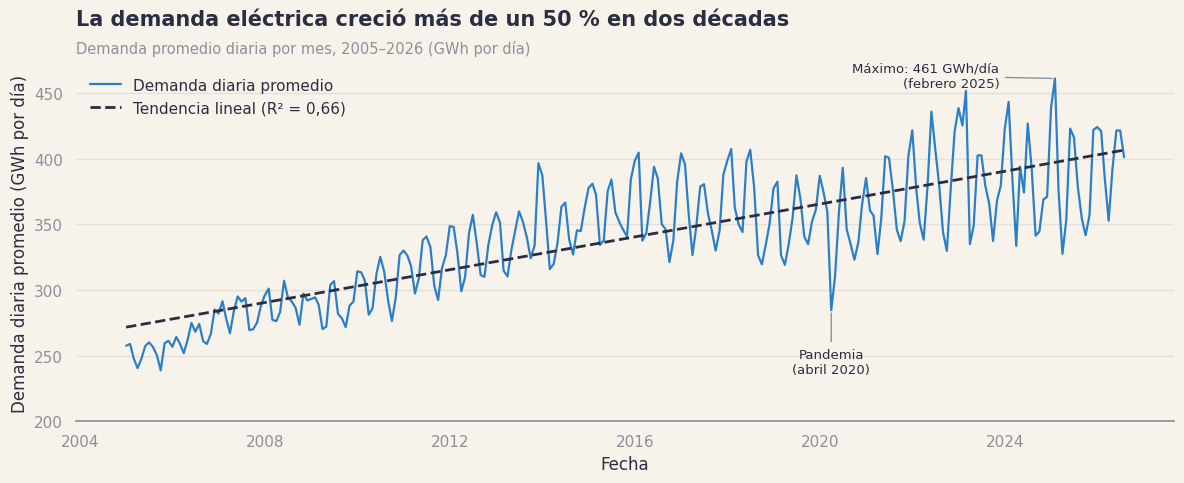

In [84]:
meses_es = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio',
            'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']

# Tendencia lineal y su R²
x = np.arange(len(df_base_mensual))
y = df_base_mensual['Demanda Diaria']
pendiente, intercepto = np.polyfit(x, y, 1)
tendencia = pendiente * x + intercepto
r2 = 1 - ((y - tendencia)**2).sum() / ((y - y.mean())**2).sum()

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(x=df_base_mensual['Período'], y=y, color='#2A7FC9', linewidth=1.6,
             label='Demanda diaria promedio', ax=ax)
ax.plot(df_base_mensual['Período'], tendencia, color=TINTA, linestyle='--', linewidth=2,
        label=f'Tendencia lineal (R² = {r2:.2f})'.replace('.', ','))

# Anotaciones: máximo de la serie y caída por la pandemia
maximo = df_base_mensual.loc[y.idxmax()]
ax.annotate(f"Máximo: {maximo['Demanda Diaria']:.0f} GWh/día\n({meses_es[maximo['Mes'] - 1]} {maximo['Año']})",
            xy=(maximo['Período'], maximo['Demanda Diaria']), xytext=(-40, -6),
            textcoords='offset points', fontsize=9.5, ha='right',
            arrowprops=dict(arrowstyle='-', color=GRIS))

pandemia = df_base_mensual[df_base_mensual['Período'] == '2020-04-01'].iloc[0]
ax.annotate('Pandemia\n(abril 2020)', xy=(pandemia['Período'], pandemia['Demanda Diaria']),
            xytext=(0, -45), textcoords='offset points', fontsize=9.5, ha='center',
            arrowprops=dict(arrowstyle='-', color=GRIS))

titulo(ax, 'La demanda eléctrica creció más de un 50 % en dos décadas',
       'Demanda promedio diaria por mes, 2005–2026 (GWh por día)')
ax.set_xlabel('Fecha')
ax.set_ylabel('Demanda diaria promedio (GWh por día)')
ax.set_ylim(200, None)
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig('evolucion_demanda_electrica_diaria.png', dpi=200)
plt.show()

La demanda diaria promedio creció de forma sostenida: pasó de unos 253 GWh por día en 2005 a 387 GWh por día en 2025, un aumento cercano al 53 %. La tendencia lineal indica un crecimiento de alrededor de 6 GWh por día por año. El crecimiento fue más rápido entre 2005 y 2015, se estancó entre 2016 y 2020 y volvió a crecer desde 2021.

Sobre esa tendencia se observa una oscilación que se repite todos los años: la serie sube y baja dentro de cada año siguiendo las estaciones, con picos en verano e invierno. El máximo de toda la serie se registró en febrero de 2025, con 461 GWh por día.

Este gráfico justifica la transformación a demanda relativa: como la demanda creció más de un 50 % en el período, comparar meses de años distintos en valores absolutos mezclaría el efecto del crecimiento con el del clima.

## 4.2 Grafico demanda y temperatura según el mes

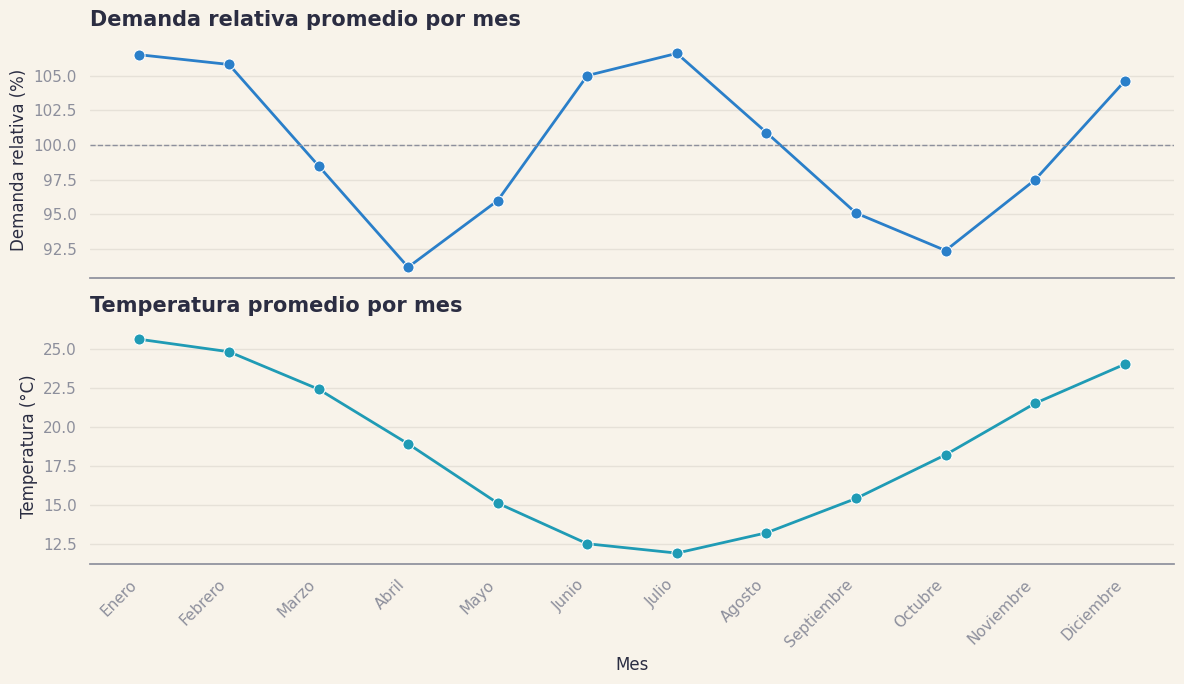

In [85]:
meses = [
    'Enero', 'Febrero', 'Marzo', 'Abril',
    'Mayo', 'Junio', 'Julio', 'Agosto',
    'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
]

fig, ejes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

sns.lineplot(x=por_mes.index, y=por_mes['Demanda Relativa'], marker='o', markersize=8,
             linewidth=2, color='#2A7FC9', ax=ejes[0])
ejes[0].axhline(100, linestyle='--', color=GRIS, linewidth=1)
ejes[0].set_ylabel('Demanda relativa (%)')
ejes[0].set_title('Demanda relativa promedio por mes', pad=12)

sns.lineplot(x=por_mes.index, y=por_mes['Temperatura Promedio'], marker='o', markersize=8,
             linewidth=2, color='#1F9BB5', ax=ejes[1])
ejes[1].set_ylabel('Temperatura (°C)')
ejes[1].set_title('Temperatura promedio por mes', pad=12)
ejes[1].set_xticks(range(1, 13))
ejes[1].set_xticklabels(meses, rotation=45, ha='right')
ejes[1].set_xlabel('Mes')

sns.despine(left=True)
plt.tight_layout()
plt.savefig('demanda_relativa_promedio_mes.png', dpi=200)
plt.show()

Este gráfico de líneas nos permite observar el patrón de la demanda eléctrica a lo largo del año, comparándolo directamente con el ciclo de temperaturas.
La demanda no es lineal respecto a la temperatura. Se observan dos picos claros: uno en los meses más fríos (junio-julio) y otro en los meses más cálidos (diciembre-febrero). Por otro lado, el bajo consumo se da en los meses templados.

El pico de invierno se explica al haber menos luz natural y utilizar calefacción eléctrica, mientras que el pico de verano se asocia al uso de aire acondicionado y ventilador. Ambos picos tienen una demanda relativa similar (alrededor del 106 % del promedio anual), por lo que el sistema eléctrico debe estar preparado para dos momentos de máxima exigencia en el año.

##4.3 Grafico demanda por estación y segmento

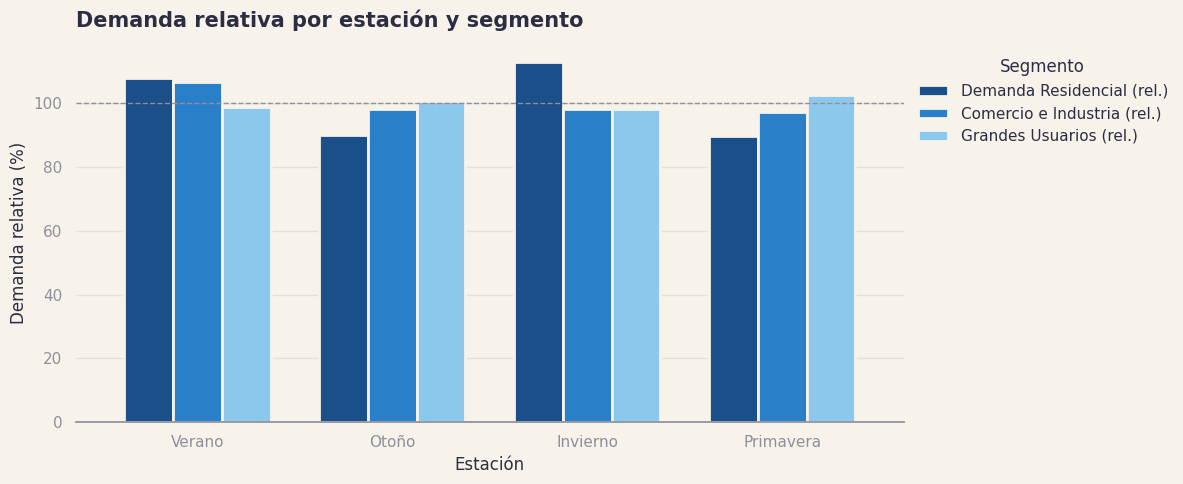

In [86]:
columnas_segmentos = [
    'Demanda Residencial (rel.)',
    'Comercio e Industria (rel.)',
    'Grandes Usuarios (rel.)'
]

colores = [colores_segmento['Demanda Residencial'],
           colores_segmento['Comercio e Industria'],
           colores_segmento['Grandes Usuarios']]

ax = por_estacion[columnas_segmentos].plot(
    kind='bar',
    figsize=(12, 5),
    color=colores,
    width=0.75,
    edgecolor=FONDO,
    linewidth=2
)

plt.axhline(100, linestyle='--', color=GRIS, linewidth=1)
plt.title('Demanda relativa por estación y segmento', pad=12)
plt.xlabel('Estación')
plt.ylabel('Demanda relativa (%)')
plt.xticks(rotation=0)
plt.legend(title='Segmento', loc='upper left', bbox_to_anchor=(1, 1))
ax.xaxis.grid(False)
sns.despine(left=True)
plt.tight_layout()

plt.savefig('demanda_relativa_estacion_segmento.png', dpi=200)
plt.show()

Observamos en este gráfico de barras la demanda relativa promedio por estación del año para los tres segmentos principales: Residencial, Comercio e Industria, y Grandes Usuarios.

El segmento Residencial muestra la mayor variación entre estaciones. Su demanda es máxima en invierno (por encima del 112%) y mínima en primavera/otoño (por debajo del 90%). Esto nos muestra que los hogares son los principales responsables de los picos estacionales del sistema.

El segmento de Comercio e Industria tiene su pico en verano (superando el 106%), probablemente por la refrigeración en locales comerciales.

Los Grandes Usuarios presentan una demanda similar en todas las estaciones (cerca del 100%), lo que demuestra que su consumo está atado a procesos productivos y no a las condiciones climáticas.

##4.4 Grafico demanda según la temperatura

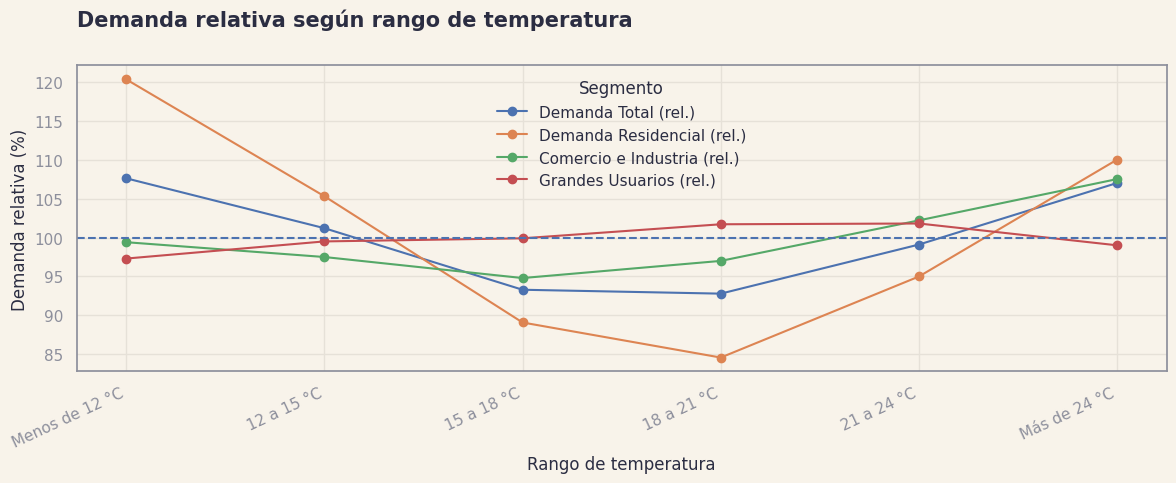

In [87]:
por_temperatura[
    [s + ' (rel.)' for s in segmentos]
].plot(
    marker='o',
    figsize=(12, 5)
)

plt.axhline(100, linestyle='--')
plt.title('Demanda relativa según rango de temperatura')
plt.xlabel('Rango de temperatura')
plt.ylabel('Demanda relativa (%)')
plt.xticks(rotation=25, ha='right')
plt.legend(title='Segmento')
plt.tight_layout()

plt.savefig('demanda_temperatura.png', dpi=200)
plt.show()

Este gráfico de líneas muestra la demanda relativa promedio agrupada por rangos de temperatura (de menos de 12°C a más de 24°C).

Se observa claramente que la demanda mínima se concentra en el rango templado de 15 a 21°C (valores cercanos al 93%). A medida que la temperatura se aleja, la demanda se dispara.
El extremo frío (menos de 12°C) genera un pico de demanda total del 107.6%, mientras que el extremo cálido (más de 24°C) genera un pico similar, de 107%.

La línea naranja (Residencial) es la que tiene la pendiente más pronunciada en ambos extremos, confirmando que es el segmento que más reacciona al frío y al calor.
La línea verde (Comercio e Industria) sube solo con el calor, y la roja (Grandes Usuarios) se mantiene casi plana.

##4.5 Grafico demanda empresa distribuidora

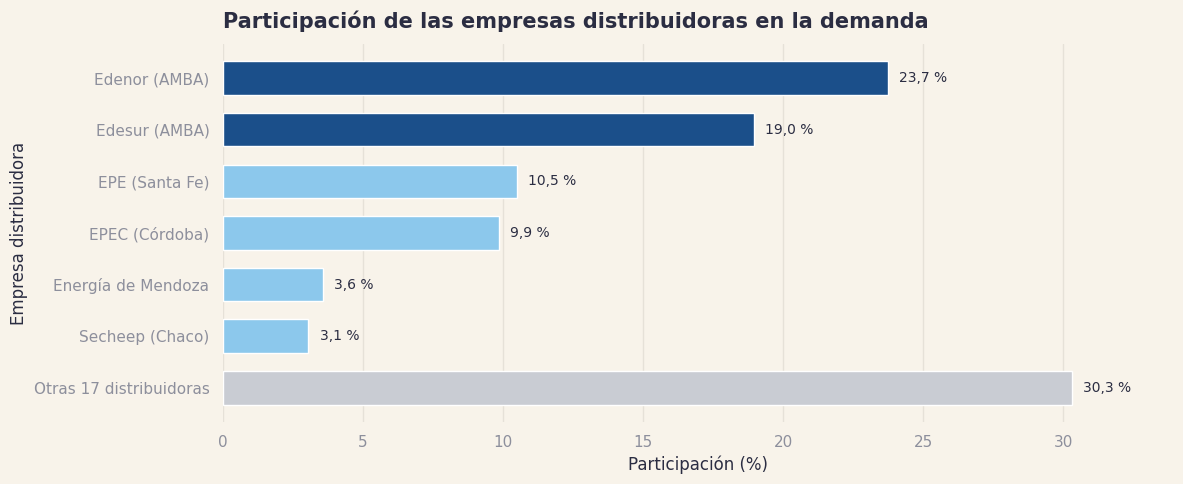

In [88]:
emp = df_empresas[(df_empresas['Frecuencia'] == 'mensual') & (df_empresas['Año'] <= 2025)]
cols_empresas = [c for c in emp.columns if c not in ['Período', 'Frecuencia', 'Año']]

demanda_empresa = emp[cols_empresas].sum().sort_values(ascending=False)
participacion = demanda_empresa / demanda_empresa.sum() * 100

# Nos quedamos con las 6 principales y agrupamos el resto en "Otras"
principales = participacion.head(6)
principales[f'Otras {len(participacion) - 6} distribuidoras'] = participacion.iloc[6:].sum()

nombres = {'EDENOR DISTRIBUIDOR': 'Edenor (AMBA)',
           'EDESUR DISTRIBUIDOR': 'Edesur (AMBA)',
           'EPESF DISTRIBUIDOR': 'EPE (Santa Fe)',
           'EPEC DISTRIBUIDOR': 'EPEC (Córdoba)',
           'ENERGIA DE MENDOZA SA': 'Energía de Mendoza',
           'SECHEEP': 'Secheep (Chaco)'}
principales = principales.rename(index=nombres)

# Azul oscuro para el AMBA, gris para "Otras" y celeste para el resto
colores = ['#1B4F8A' if 'AMBA' in n else '#C9CCD3' if 'Otras' in n else '#8CC8EC'
           for n in principales.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(principales.index, principales.values, color=colores, height=0.65)
ax.invert_yaxis()

for i, valor in enumerate(principales.values):
    ax.text(valor + 0.4, i, f'{valor:.1f} %'.replace('.', ','), va='center', fontsize=10, color=TINTA)

ax.set_title('Participación de las empresas distribuidoras en la demanda', pad=12)
ax.set_xlabel('Participación (%)')
ax.set_ylabel('Empresa distribuidora')
ax.xaxis.grid(True)
ax.yaxis.grid(False)
ax.set_xlim(0, principales.max() * 1.12)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig('empresas_distribuidoras.png', dpi=200)
plt.show()

Este gráfico de barras muestra la participación porcentual de cada empresa distribuidora en la demanda conjunta de las principales distribuidoras, entre 2014 y 2025.

El mercado está dominado por Edenor y Edesur, que juntas explican una parte muy significativa del consumo. Esto es esperable, ya que cubren la región más poblada y con mayor actividad económica del país (AMBA). Las demás distribuidoras tienen participaciones mucho menores.

Estas distribuidoras explican en conjunto alrededor del 71 % de la demanda total; el resto corresponde principalmente a grandes usuarios que compran directamente en el mercado mayorista.

## 4.6 Grafico demanda eléctrica según temperatura y estación


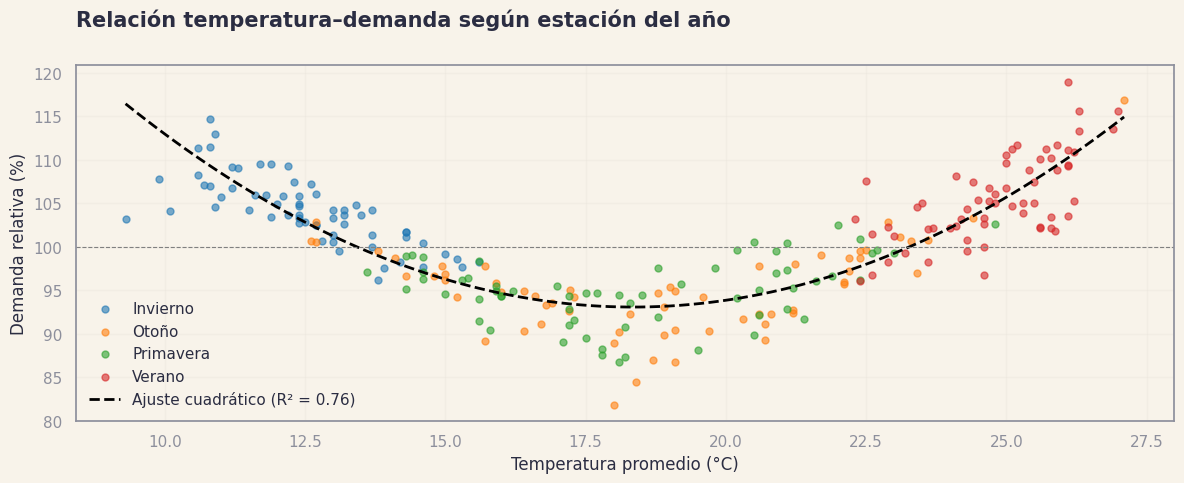

In [89]:
dat = df_base_mensual.dropna(subset=['Demanda Total (rel.)'])
x = dat['Temperatura Promedio']
y = dat['Demanda Total (rel.)']

coef = np.polyfit(x, y, 2)
y_pred = np.polyval(coef, x)
r2 = 1 - ((y - y_pred)**2).sum() / ((y - y.mean())**2).sum()

colores = {'Verano': 'tab:red', 'Otoño': 'tab:orange', 'Invierno': 'tab:blue', 'Primavera': 'tab:green'}
plt.figure(figsize=(12, 5))
for est, grupo in dat.groupby('Estación'):
    plt.scatter(grupo['Temperatura Promedio'], grupo['Demanda Total (rel.)'], color=colores[est], label=est, alpha=0.6, s=25)

x_curva = np.linspace(x.min(), x.max(), 100)
plt.plot(x_curva, np.polyval(coef, x_curva), color='black', linestyle='--', linewidth=2, label=f'Ajuste cuadrático (R² = {r2:.2f})')

plt.axhline(100, linestyle='--', color='gray', lw=0.8)
plt.xlabel('Temperatura promedio (°C)')
plt.ylabel('Demanda relativa (%)')
plt.title('Relación temperatura–demanda según estación del año')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('dispersion_temperatura.png', dpi=200)
plt.show()

Este gráfico de dispersión muestra cada mes del dataset con un punto (Temperatura vs. Demanda Relativa), coloreado por estación, formando una parábola.

Se ve claramente cómo los puntos rojos (Verano) se agrupan a la derecha, lo cual habla de altas temperaturas y alta demanda; los azules (Invierno) a la izquierda, referido a las bajas temperaturas y alta demanda; y los verdes/naranjas (Primavera/Otoño) en el centro con demanda baja.
La dispersión de los puntos en esta zona central (15-20°C) indican que, cuando el clima es templado, otros factores toman mayor relevancia relativa para las variaciones de demanda.